## A simulation of a real star (Sirius) with an ecliptic orbit, using coordinates from Gaia data as (x, y) data points

### 1- Important libraries importing

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astroquery.gaia import Gaia
from astropy.coordinates import SkyCoord
import astropy.units as u



The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


### 2- Connect to the Gaia server & pulls Sirius data like:

- source_id : The unique ID of the star
- ra : Right Ascension
- dec : Declination
- parallax : in Millisecond (mas)
- pmra, pmdec : Proper Motion
- phot_g_mean_mag :

In [2]:
print("Conecting to Gaia Servers, please wait..")

coord = SkyCoord(ra = 101.28715533, dec= 16.71611586, unit = (u.degree, u.degree), frame= 'icrs')
ra_val =float(coord.ra.deg)
dec_val = float(coord.dec.deg)
query = f"""
SELECT source_id, ra, dec, parallax, pmra, pmdec, phot_g_mean_mag 
FROM gaiadr3.gaia_source
WHERE CONTAINS (POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra_val},{dec_val}, 0.01)) =1;
"""


job = Gaia.launch_job(query)
results = job.get_results()

if len(results) > 0:
    star = results[0]
    print(f"Star ID: {star['source_id']} is found!")
    print(f"RA: {star['ra']}, Dec: {star['dec']}")
    print(f"Parallax: {star['parallax']}")
else:
    print("Still couldn't find it.")

Conecting to Gaia Servers, please wait..
Star ID: 3357988294543583616 is found!
RA: 101.28697729504599, Dec: 16.707323109862806
Parallax: 1.2244934848627758


In [4]:
parallax = star['parallax'] 
pmra = star['pmra'] 
pmdec = star['pmdec']

days = np.linspace(0, 365, 100)


### 3- Equation of Motion: 

- Part 1 (Parallax): parallax * np.cos(...) and parallax * np.sin(...). This equation draws a circle (or an ellipse) that repeats every 365 days. (This is the effect of the Earth's rotation.)

- Part 2 (Proper Motion): pmra * days / 365. This is a linear equation, because the star moves in a straight line as the days pass.


#### Conclusion: 
Combining the two equations gives us a “spiral” or an elliptical shape moving in a straight line. And that is exactly what we see in the sky!




In [5]:
x_data = (parallax * np.cos(2 * np.pi * days / 365)) + (pmra * days / 365)
y_data = (parallax * np.sin(2 * np.pi * days / 365)) + (pmdec * days / 365)

### 4- Matplotlib plotting our data :

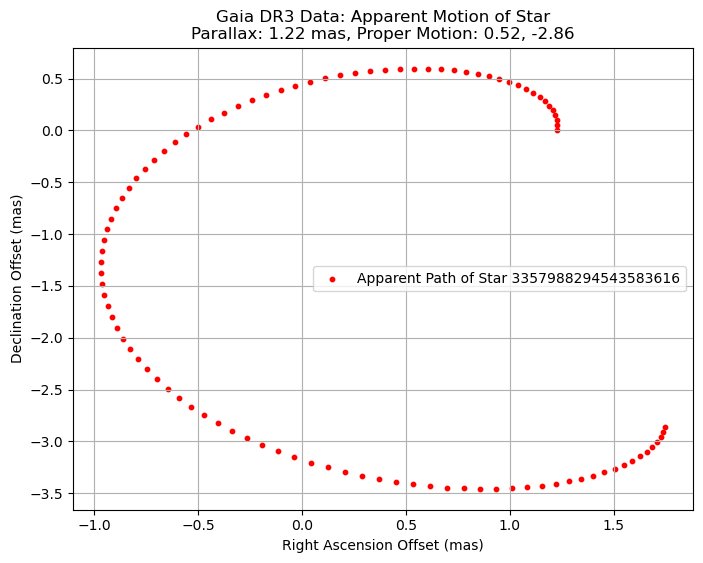

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(x_data, y_data, color='red', s=10, label=f'Apparent Path of Star {star["source_id"]}')

plt.title(f"Gaia DR3 Data: Apparent Motion of Star\nParallax: {parallax:.2f} mas, Proper Motion: {pmra:.2f}, {pmdec:.2f}")
plt.xlabel("Right Ascension Offset (mas)")
plt.ylabel("Declination Offset (mas)")
plt.grid(True)
plt.legend()
plt.show()